# Introduction to Qiskit

Qiskit is an open-source library allowing users to design quantum circuits and excute them on either simulators or real quantum machines. Though mainly developed and publicized by IBM, it allows running circuits on different providers, such that IBM of course, but also AWS for instance.

In this tutorial, our goal will be to give a quick presentation of the basics of Qiskit. At the end of the session, you should be able to create your own quantum circuits and understand the inner workings of Qiskit at a high-level.

There are three main steps in the execution of a quantum circuit:
 1. Its design.
 2. Its transpilation.
 3. Its execution.

If you run Qiskit locally (that is, not on [littlesthub.r2.enst.fr](littlesthub.r2.enst.fr)), run this cell beforehand:

In [1]:
!pip install qiskit matplotlib qiskit-ibm-runtime pylatexenc qiskit-aer sympy scipy tqdm

## 1. Designing quantum circuits
Creating a quantum circuit is simple enough in Qiskit. First of all, we import the relevant class:

In [2]:
from qiskit.circuit import QuantumCircuit

Then we instantiate it:

In [3]:
qc = QuantumCircuit(2)

The [`QuantumCircuit` class](https://docs.quantum.ibm.com/api/qiskit/qiskit.circuit.QuantumCircuit) may take several arguments to be instantiated. What to remember for now is that:
 - The first argument indicates the number of qubits.
 - The second argument indicates the number of classical bits. If not specified, it defaults to $0$.

### Applying gates
We now want to apply gates to our quantum circuit. For instance, if we want to create a circuit creating the first bell state, namely:
$$\frac{|00\rangle+|11\rangle}{\sqrt{2}},$$
we have to first apply an $H$ gate on the first qubit and a CNOT gate on the second one controlled off the first.

#### Using `QuantumCircuit`'s methods
This can be done via in-place methods like this:

In [4]:
qc.h(0)
qc.cx(0, 1)

Finally, we can visualize our circuit using the `draw` method:

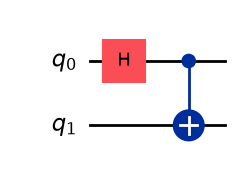

In [5]:
qc.draw("mpl")

A small trick to know is that the circuit will only print if it's the last instruction of the cell. For instance:

In [6]:
qc.draw("mpl")
a = 1

In order for the circuit to show up no matter what, you can use the `display` function of Jupyter notebooks:

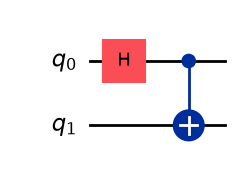

In [7]:
display(qc.draw("mpl"))
a = 2

Wires in qiskit are indexed in a natural way top-to-bottom: the `0` index corresponds to the first wire.

There are some general rules of thumb when it comes to applying gates in Qiskit, namely:
 - If it is a controlled gate, the first arguments will be the controls, and the next ones the qubits the gate applies to.
 - If it is a parametrized gate, the parameter is the first argument, preceding the potential controls.
 - If a gate can be implemented via an in-place method like `g`, its controlled version can often be applied in place using the `cg` method. For instance, `ch` allows to apply a controlled Hadamard gate.

### Question
Try to apply an $RX\left(\frac\pi4\right)$ gate on the first qubit conditioned on the second one being in state $|1\rangle$:

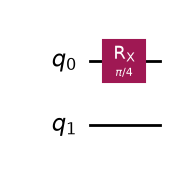

In [8]:
import numpy as np

qc = QuantumCircuit(2)
qc.rx(np.pi/4, 0)
qc.draw("mpl")

#### Using the `append` method
It may happen that we want to apply a gate that isn't represented as a direct method of `QuantumCircuit`, or to use a quantum circuit as a gate on another. It is possible to do so using the `append` method of a quantum circuit.

For instance, let us say that we want to apply a `C3SXGate`. This gate is [directly available in Qiskit](https://docs.quantum.ibm.com/api/qiskit/0.40/qiskit.circuit.library.C3SXGate), so what we can do is import it and then append it to our quantum circuit, like so:

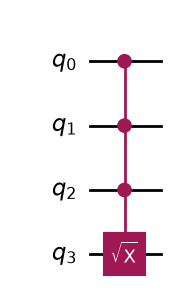

In [9]:
from qiskit.circuit.library import C3SXGate

qc = QuantumCircuit(4)
qc.append(C3SXGate(), [0, 1, 2, 3])
qc.draw("mpl")

The `append` method takes **an instance** of a `Gate` object and **a list** of the qubits it is applied to. It is totally possible to mix the order of the last parameter to control on other qubits, like so:

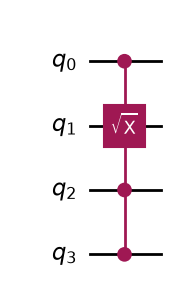

In [10]:
qc = QuantumCircuit(4)
qc.append(C3SXGate(), [0, 3, 2, 1])
qc.draw("mpl")

Furthermore, note that `QuantumCircuit` has a `to_gate` method, which allows to convert a `QuantumCircuit` object to a `Gate` one, which can then be used as a normal gate. You can even pass a name to this method:

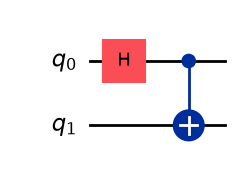

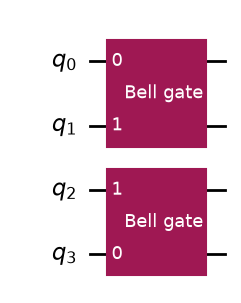

In [11]:
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
display(qc.draw("mpl"))
bell_gate = qc.to_gate(label="Bell gate")

qc2 = QuantumCircuit(4)
qc2.append(bell_gate, [0, 1])
qc2.append(bell_gate, [3, 2])
qc2.draw("mpl")

You can then use the `decompose` method to get back the gates you actually apply:

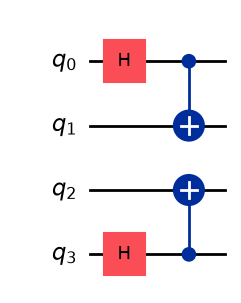

In [12]:
qc2.decompose().draw("mpl")

Note that the `decompose` method isn't recursive: it will only decompose to the next possible level. For instance, the following gives a circuit in terms of even more basic gates:

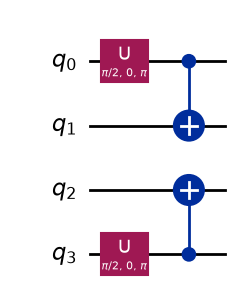

In [13]:
qc2.decompose().decompose().draw("mpl")

Since it can happen that the number of `decompose` that we have to apply is quite large, it is possible to directly specify the number of times we want to apply this function, which may be convenient:

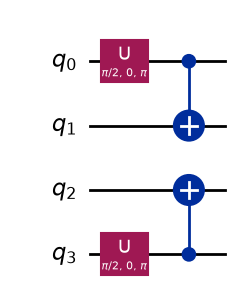

In [14]:
qc2.decompose(reps=2).draw("mpl")

Note that `decompose` isn't purely visual: it returns a new quantum circuit.

### Creating custom unitary gates
For simulation purposes, it may be useful to tell Qiskit to apply some unitary gate even if it isn't in the standard library. We just have to use the `UnitaryGate` class to do so.

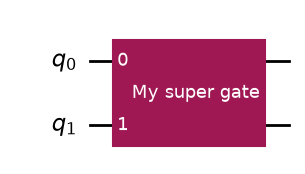

In [15]:
import numpy as np
from qiskit.circuit.library import UnitaryGate

my_custom_gate = UnitaryGate(
    np.array(
        [
            [1, 1, 1, 1],
            [-1, -1, 1, 1],
            [-1j, 1j, 1j, -1j],
            [-1j, 1j, -1j, 1j]
        ]
    ) / 2,
    label="My super gate"
)
qc = QuantumCircuit(2)
qc.append(my_custom_gate, [0, 1])
qc.draw("mpl")

If simple enough, Qiskit can even try to break it down for you!

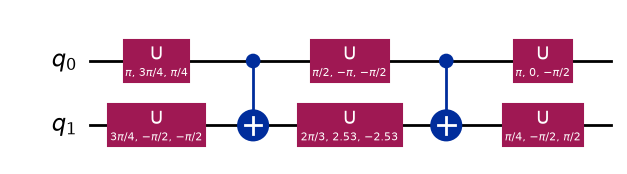

In [16]:
qc.decompose().draw("mpl")

Note that you can also access the inverse gate by simply calling `inverse`:

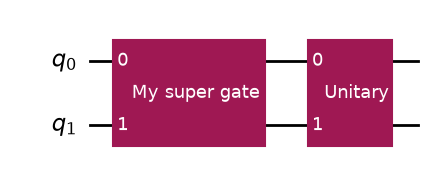

In [17]:
inverse_gate = my_custom_gate.inverse()
qc.append(inverse_gate, [0, 1])
qc.draw("mpl")

You can also create a controlled version of this gate using the `control` method:

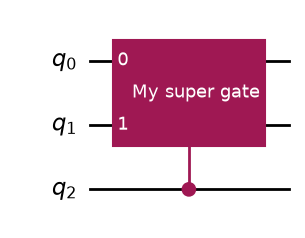

In [18]:
qc = QuantumCircuit(3)
# Control on the third qubit
qc.append(my_custom_gate.control(), [2, 0, 1])
qc.draw("mpl")

## Exercise: uncomputing
A nice trick in quantum computing is uncomputing. Uncomputing is the process of applying the inverse of the gates you apply to an ancilla system so that it resets to the $|0\rangle$ state. It may not be clear, so let us take an example.

Say that we have a function $\theta$ that takes as input a bitstring $x$ and returns an angle $\theta_x$ as a bitstring (say, as a fixed point number between $0$ and $1$). We want to find an unitary that performs the following mapping:
$$U|x\rangle=\mathrm{e}^{2\mathrm{i}\pi\theta_x}|x\rangle.$$
Note that this inded defines an unitary: it's a diagonal matrix with unit complex numbers on the diagonal. So clearly, we should be able to implement it.

As it turns out, a clever way to do this operation uses *ancilla* qubits. These qubits are used in the computation but are not part of the final result. That is, we will design a unitary that performs the following mapping:
$$\widetilde{U}|x, 0\rangle=\mathrm{e}^{2\mathrm{i}\pi\theta_x}|x,0\rangle.$$
We don't specify the way this unitary acts if the ancilla qubits are not in the $|0\rangle$ state: we simply guarantee that if this is the case, they will leave the gate in the same state.

So, how can we use these ancilla qubits? First, note that it is totally possible to perform the following mapping:
$$V|y\rangle=\mathrm{e}^{2\mathrm{i}\pi y}|y\rangle.$$

Using an oracle $U_{\theta}$ that implements $\theta$ and $V$, how can you perform the desired mapping? In this exercise, you're being given $U_\theta$ and $V$. The first register is a single qubit, and the second one, containing $\theta_x$, is 3 qubit-large.

In [19]:
V = QuantumCircuit(3)
V.z(0)
V.s(1)
V.t(2)
V = V.to_gate(label="V")

U_theta = UnitaryGate(np.array([
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0], 
    [0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
    [0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
    [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
    [0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
    [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
]), label="U_theta")

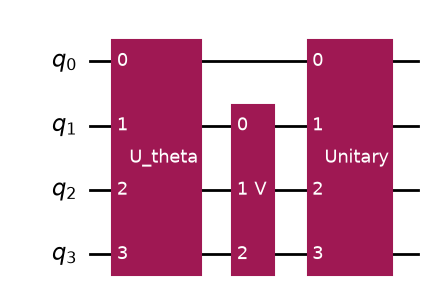

In [20]:
qc = QuantumCircuit(4)

qc.append(U_theta, range(4))
qc.append(V, range(1,4))
qc.append(U_theta.inverse(), range(4))

qc.draw("mpl")

In [21]:
from qiskit.quantum_info import Operator
def test_uncomputing(qc):
    op = Operator(qc).data
    zero_state = np.zeros((1,16))
    assert np.allclose(op[1:, 0], 0), "The circuit doesn't produce the right unitary"
    assert np.allclose(np.angle(op[0, 0]) % (2 * np.pi), 5 * np.pi / 4), "The circuit doesn't produce the right unitary"
    assert np.allclose(op[:1, 1], 0), "The circuit doesn't produce the right unitary"
    assert np.allclose(op[2:, 1], 0), "The circuit doesn't produce the right unitary"
    assert np.allclose(np.angle(op[1, 1]) % (2 * np.pi), np.pi / 2), "The circuit doesn't produce the right unitary"
    print("Congratz!")

test_uncomputing(qc)

Congratz!


### Measuring
In order to apply measurements on a `QuantumCircuit`, we first have to specify the number of classical bits that we'll be using when creating it. For instance:

In [22]:
qc = QuantumCircuit(2, 3)

Thie `QuantumCircuit` has `2` qubits and `3` bits. We can then apply a measurement by specifying the qubits to measure, and the classical bits to store the result into:

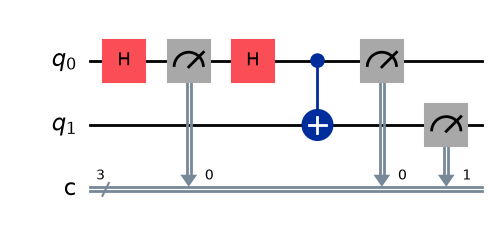

In [23]:
qc.h(0)
qc.measure(0, 0)
qc.h(0)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])
qc.draw("mpl")

Note that in this example, one classical bit is unused, and thus will always be $0$, while the classical bit indexed `0` is rewritten after having been set once, which is probably not the smartest thing to do.

### Parametrized gates

The last thing we need to see concerning circuit building is parametrized gates. The concept is fairly simple to understand: gates that accept an additional argument like a rotation parameter can instead accept an instance of a [`Parameter`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.Parameter), like so.

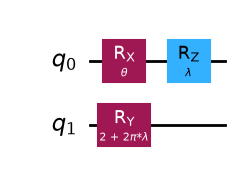

In [24]:
from qiskit.circuit import Parameter

my_param_1 = Parameter(r"$\theta$") # Parameters' names can be LaTeX-typed
my_param_2 = Parameter(r"$\lambda$")

qc = QuantumCircuit(2)
qc.rx(my_param_1, 0)
qc.rz(my_param_2, 0)
qc.ry(2 * my_param_2 * np.pi + 2, 1) # We can polynomially transform a parameter
qc.draw("mpl")

We can then get the resulting circuit by assigning values to these parameters using the `assign_parameters` method, which takes as input a dictionary having the parameters as keys and their associated values as values.

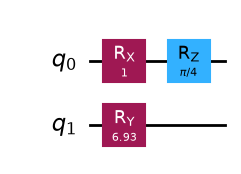

In [25]:
qc_assigned = qc.assign_parameters({
    my_param_1: 1,
    my_param_2: np.pi / 4
})
qc_assigned.draw("mpl")

## Exercise: Variational circuits

The reason why we care about parameters in quantum circuits is mainly variational algorithms. Variational algorithms essentially consist of the following steps:
 1. We design a quantum circuit with different parameters, which we call our **ansatz**.
 2. We assign a random value to these parameters, and evaluate the output of the quantum circuit using a **loss function**, just like in Machine Learning.
 3. A classical optimizer takes as input the parameters we assigned to our quantum circuit along with the output of our loss function and returns a new set of parameters to evaluate our circuit on.
 4. Repeat until the loss function is minimized.

Conceptually, the goal is to leverage what quantum computing is good at, namely sampling outputs from quantum circuits, and let classical computers do the optimization part, since there's not really a point in doing this step on a quantum computer. Variational algorithms are a very promising area of quantum computing, and are expected to be the ones using which we can declare a true quantum advantage.

Of course, not every problem is suited to be tackled by a variational algorithm. It depends on whether the problem can be described by a loss function that can be efficiently evaluated by sampling a quantum circuit. For instance, if an Hermitian matrix as a sparse Pauli decomposition, then it is possible to compute its lowest eigenvalue in time $\mathcal{O}\left(\frac{N}{\varepsilon^2}\right)$, with $N$ being the number of Pauli terms in the decomposition and $\varepsilon$ is a precision parameter using the VQE algorithm, which has applications in chemistry.

In this exercise, we will try to solve the following problem using a variational algorithm: can we find a quantum circuit that prepares a quantum state such that:
 - if we measure it, we get $\ket{0}$ with probability $\frac12$;
 - if we apply an $H$ gate on it and then measure it, we get $\ket{0}$ with probability $p$
with $p$ being given.

Your goal is to design the most efficient ansatz possible in terms of depth and number of parameters that can tackle this problem.

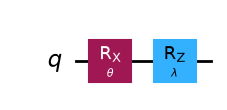

In [26]:
qc = QuantumCircuit(1)

my_param_1 = Parameter(r"$\theta$") # Parameters' names can be LaTeX-typed
my_param_2 = Parameter(r"$\lambda$")

qc.rx(my_param_1, 0)
qc.rz(my_param_2, 0)

qc.draw("mpl")

In order to judge an ansatz, we need a loss function suited for our problem. Here, we will evaluate an ansatz using the following formula
$$f(\theta) = \left(\mathbb{P}[\ket{0}|\theta]-\frac12\right)^2+(\mathbb{P}[H\ket{0}|\theta]-p)^2$$
with $\mathbb{P}[\ket{0}|\theta]$ being the probability of measuring $\ket{0}$ using the vector of parameters $\theta$ and $\mathbb{P}[H\ket{0}|\theta]$ being the probability of measuring $\ket{0}$ using the vector of parameters $\theta$ and having applied an $H$ gate beforehand.

The following code runs the optimization routine and prints your final score.

In [27]:
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import Pauli
from scipy.optimize import minimize

def loss(qc, theta, p):
    estimator = StatevectorEstimator()
    evs = estimator.run([(qc, [Pauli("Z"), Pauli("X")], theta)]).result()[0].data.evs
    p0 = (1 + evs[0]) / 2
    ph0 = (1 + evs[1]) / 2

    return pow(p0 - 1/2, 2) + pow(ph0 - p, 2)

def evaluate_ansatz(qc, p):
    num_params = qc.num_parameters
    initial_params = 2 * np.pi * np.random.random(num_params)
    res = minimize(
        fun = lambda theta: loss(qc, theta, p),
        x0 = initial_params,
        method = "COBYLA"
    )
    return res.x, loss(qc, res.x, p)

params, score = evaluate_ansatz(qc, 0.2)
print(f"Optimal parameters: {params}. Score: {score}.")

Optimal parameters: [3.78511053 1.57079388]. Score: 4.648795251673549e-11.


## Transpiling
If we want to run our quantum circuit on a real Quantum machine, we first have to take two limitations into account:
 1. A quantum computer can only implement a certain set of basic gates.
 2. A quantum computer can only implement controlled operations on adjacent qubits.

Throughout this session, we'll take the Paris machine as an example. The goal of this part is only for you to understand concepts, not code, so you don't have to worry about it for now. Our goal will be to create the first Bell State on this machine.

Since the Paris machine is retired, we'll use a fake backend to emulate it.

In [28]:
from qiskit_ibm_runtime.fake_provider import FakeParisV2

backend = FakeParisV2()

First of all, let's check how many qubits this machine has:

In [29]:
backend.num_qubits

27

It means that we're supposed to be able to implement any $2^{27}\times2^{27}$ unitary matrix. Let's check which gates this backend actually supports:

In [30]:
backend.configuration().basis_gates

['id', 'rz', 'sx', 'x', 'cx', 'reset']

That... is not a lot, is it?

Well, it's not, but it's sufficient for our needs! In fact, it is possible to show that we can approximate any unitary as close as we want using only these gates. Of course, this can lead to quite deep circuits though...

You can think as these operations as the same as those a classical processor supports. Though a classical processor doesn't directly know how to compute a square root, we can design a circuit to compute it using the operations the processor actually supports. It's no different here.

So, let us create a quantum circuit and try to run it on this backend! For that, we'll need a `SamplerV2` object, whose goal is simply to run the quantum circuit a certain number of times and return the counts. Note that the `run` method of a `SamplerV2` instance expects a **list** of quantum circuits (amongst other things).

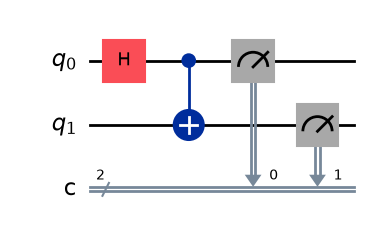

In [31]:
from qiskit_ibm_runtime import SamplerV2

qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])
display(qc.draw("mpl"))

sampler = SamplerV2(mode=backend)
job = sampler.run([qc])

Just like we expected, the machine isn't able to run our circuit because it contains some instructions it doesn't understand. One of the step of transpiling is to do just that: rewrite a circuit in terms of the gates that are accepted by the backend. So, let us transpile this circuit using the `generate_preset_pass_manager` function.

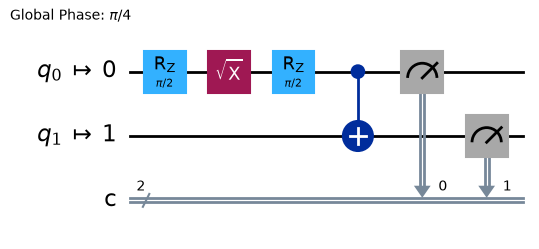

In [32]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
qc_transpiled = pm.run(qc)
qc_transpiled.draw("mpl", idle_wires=False)

Now, we could actually run our circuit on the quantum machine! 

In [33]:
job = sampler.run([qc_transpiled])
print(job.result())

PrimitiveResult([SamplerPubResult(data=DataBin(c=BitArray(<shape=(), num_shots=4096, num_bits=2>)), metadata={'circuit_metadata': {}, 'executor': {'shots': 4096, 'circuit_metadata': {}, 'simulator_metadata': {'time_taken_parameter_binding': 0.002336354, 'time_taken_execute': 0.049131457, 'omp_enabled': True, 'max_gpu_memory_mb': 0, 'max_memory_mb': 5927, 'parallel_experiments': 1}}})], metadata={'executor': Metadata(chunk_timing=[]), 'options': {'default_shots': 4096, 'dynamical_decoupling': {'enable': False, 'sequence_type': 'XX', 'extra_slack_distribution': 'middle', 'scheduling_method': 'alap', 'skip_reset_qubits': False}, 'execution': {'init_qubits': True, 'rep_delay': None, 'scheduler_timing': False, 'stretch_values': False, 'meas_type': 'classified'}, 'twirling': {'enable_gates': False, 'enable_measure': False, 'group': 'pauli', 'num_randomizations': 'auto', 'shots_per_randomization': 'auto', 'strategy': 'active-accum'}, 'max_execution_time': None, 'simulator': {'angle_decimals':

We'll see later on how to use the `result` method to obtain the results we're interested in. This is not the only thing transpiling does. For instance, we've talked about the connectivity of a quantum computer. This is also known as a coupling map, and can be printed like this:

NOTE FROM PETER: This previously threw an error on ubuntu where I needed to run `sudo apt-get install -y libgvplugin-neato-layout8`

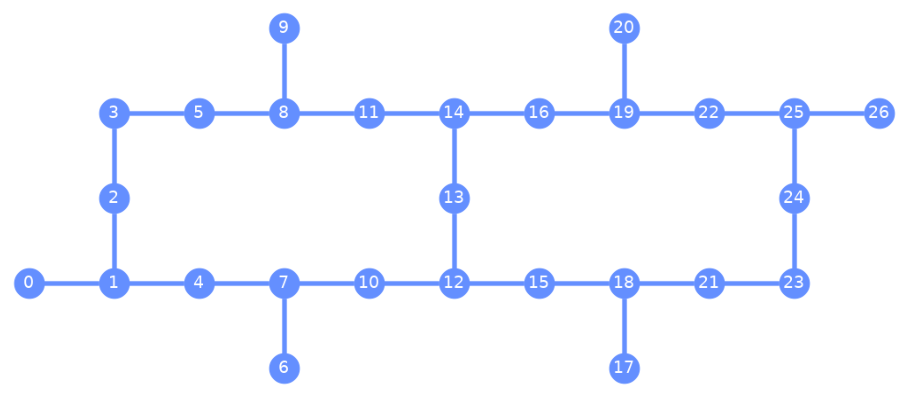

In [34]:
from qiskit.visualization import plot_gate_map

plot_gate_map(backend)

So, what happens if we ty to create the first Bell state between the first qubit and the 27th one? Well, let's try!

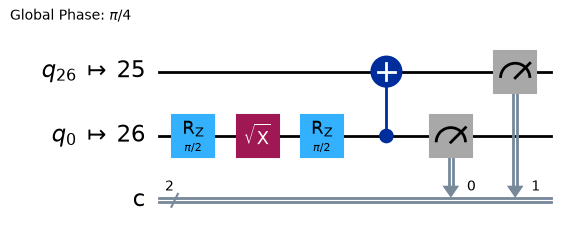

In [35]:
qc = QuantumCircuit(27, 2)
qc.h(0)
qc.cx(0, 26)
qc.measure([0, 26], [0, 1])
qc_transpiled = pm.run(qc)
qc_transpiled.draw("mpl", idle_wires=False)

The transpiler detected that we were trying to use a 2-qubit gate between two non-connected qubits and took care of changing the layout for us. Isn't that neat? :)

Of course, it is possible to specify to the transpiler the layout we want to use instead of letting it decide for us, but that's not the point of this tutorial.

As a funny anecdote (I mean, in the theoretical quantum computer science community at least, we're fun to hang out with), deciding of the optimal layout and the SWAP gates to apply being given the quantum circuit and the coupling map is an NP-hard problem, which we can't efficiently solve, even using quantum computers.

## Running a quantum circuit
At long last, we can finally see how to run a quantum circuit. There is (almost) no difference between simulating a quantum circuit classically and running it on a quantum machine from a coding point of view: this abstraction is captured by the primitives, like `SamplerV2`.

We'll talk about two kinds of primitives: the Sampler and the Estimator.

### The Sampler
A Sampler prepares a quantum state $|\psi\rangle$ by applying a quantum circuit on the all-$|0\rangle$ state, and then measure in the computational basis, returning the result. Simple enough right?

For instance, let's take back the example of a Bell state that we measure in the computational basis, and let's use the `StatevectorSampler` from `qiskit` for that:

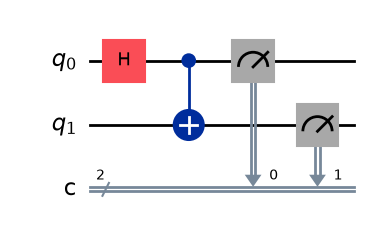

In [48]:
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])
qc.draw("mpl")

Now, we import `StatevectorSampler` and run it:

In [49]:
from qiskit.primitives import StatevectorSampler

sampler = StatevectorSampler(default_shots=10_000, seed=42)
job = sampler.run([qc])
result = job.result()

Note that `StatevectorSampler` is a classical simulator that runs locally, which is why here it gives back a result almost instantly. Finally, we can access the results like this:

In [50]:
print(result[0].data.c.get_counts())

{'11': 4985, '00': 5015}


First of all, note that `result` is a `list`: since we can pass the `run` method a `list` of quantum circuits to sample from, it is natural that the result of the job is also a `list`, with its `i`-th element corresponding to the `i`-th quantum circuit.

A small remark on the `c` attribute here. Since it is possible to have multiple classical registers in a quantum circuit, it seems natural to separate the results between the different registers. The choice that has been made for this is to index the results by the name of the classical registers. By default, the name of such a register is `c`, which is why we need this `.c` when accessing the results. If you want, you can also name a classical register like so:

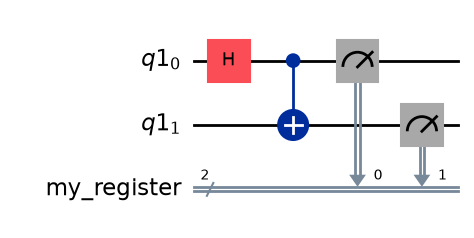

In [53]:
from qiskit import ClassicalRegister, QuantumRegister

cr = ClassicalRegister(2, "my_register")
qr = QuantumRegister(2)

qc = QuantumCircuit(qr, cr)
qc.h(0)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])
qc.draw("mpl")

We would then access the results like so:

In [54]:
sampler = StatevectorSampler(default_shots=10_000, seed=42)
job = sampler.run([qc])
result = job.result()
print(result[0].data.my_register.get_counts())

{'11': 4985, '00': 5015}


The reason why it might be useful is that `c` might not always be the default name of the classical register, especially if you create multiple `QuantumCircuits` or work in a notebook, in which cases its name might be `c2` for instance, in which case it might be convenient to name the classical register oneself.

#### A small note on `measure_all`
Qiskit has a convenience function called `measure_all`, that measures all the qubits in a classical register. One must note that this method creates a new quantum register called `meas`. So to use it, we would do in this case:

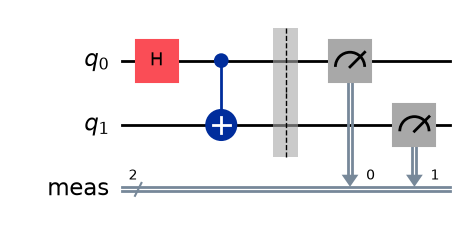

{'11': 4985, '00': 5015}


In [55]:
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()
display(qc.draw("mpl"))
sampler = StatevectorSampler(default_shots=10_000, seed=42)
job = sampler.run([qc])
result = job.result()
print(result[0].data.meas.get_counts())

Note that the `QuantumCircuit` is created without a classical register, and that we access the counts using `meas` instead of `c`. Had you created a classical register and used `c`, you'd just get `00` all the time, since no result would have been stored within the classical register `c`.

### The Estimator
An Estimator is often used in the context of variational algorithms. It not only takes a quantum circuit to create a quantum state $\ket{\psi}$ but also an observable $O$ in order to compute the expectation value $\langle\psi|O|\psi\rangle$. It will take care of measuring in different bases for you, so that you don't have to create multiple ansatzes. For instance, let's create the $\frac12IX-2XX$ observable:

In [56]:
from qiskit.quantum_info import SparsePauliOp

# I'm lying to you as we'll see later, but for now it'll work just fine :)
observable = SparsePauliOp.from_list([
    ("IX", 1/2),
    ("XX", -2)
])

We now import the Estimator and use its `run` method. This method takes a list of Primitive Unified Block (PUB for short). A PUB is a tuple containing:
 - a quantum circuit;
 - an observable;
 - an array of parameters, if the quantum circuit is parametrized.

So, in our case, since our circuit isn't parametrized, this gives us:

In [61]:
from qiskit.primitives import StatevectorEstimator

estimator = StatevectorEstimator()
qc = QuantumCircuit(2)
job = estimator.run([(qc, observable)])
result = job.result()
print(result)

PrimitiveResult([PubResult(data=DataBin(evs=np.ndarray(<shape=(), dtype=float64>), stds=np.ndarray(<shape=(), dtype=float64>)), metadata={'target_precision': 0.0, 'circuit_metadata': {}})], metadata={'version': 2})


Qiskit is mad because we included measurements in our circuit. Since it's supposed to add unitary gates at the end of it, it wouldn't make sense. So, we have to define our quantum circuit without the measures at the end:

In [62]:
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)

estimator = StatevectorEstimator()
job = estimator.run([(qc, observable)])
result = job.result()

Similarly to the Sampler, the result is in fact a list for each PUB passed to the `run` method. We can then access the expectation value using the `evs` attribute of the `data` attribute:

In [63]:
print(result[0].data.evs)

-1.9999999999999996


### A note on exact simulation

Behind the scenes, what `StatevectorSampler` and `StatevectorEstimator` do is that they create the statevector associated to the quantum circuit we provide them with and simply perform their computations from there. In particular, they won't be able to deal with a large number of qubits. It's of course possible to get the unitary matrix or only the statevector associated to a `QuantumCircuit` using the `qiskit.quantum_info` module:

In [ ]:
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import array_to_latex

qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)

display(array_to_latex(Statevector(qc).data))
display(array_to_latex(Operator(qc).data))

## Running on a real quantum machine (OPTIONAL)
As mentioned previously, there are almost no differences between running a program locally and using a quantum machine. The difference lies in the primitive you use to run this program. There are two places where you can find primitives:

 - In `qiskit` directly, where the primitives are `StatevectorSampler` and `StatevectorEstimator`. These two primitives are *classical*: they compute the state vector of the quantum circuit (hence the name) and then sample from the resulting distribution. In particular, you won't have the option to run your program using a quantum machine using those.
 - In `qiskit_ibm_runtime`, where the primitives are `SamplerV2` and `EstimatorV2`. When instantiating these primitives, you have to pass a backend on which they'll run. This backend can be a quantum machine like `FakeParisV2()` above, or a classical simulator, such that `qiskit_aer.AerSimulator`.

First and foremost, in order to use a real quantum machine, you have to set up your account. To do so, you need to follow the following steps:

1. Go to the [upgraded IBM Quantum Platform](https://quantum.cloud.ibm.com/).
2. Check that you log in using the same email you registered for this event with.
3. Go to the top right corner of the above picture and create your API token and copy it.
4. In the cell below, set `your_api_key` with your API key.
5. Click on the "Create an instance" button.
6. After the instance is created, copy its associated CRN code.
7. In the cell below, set `your_crn` with your CRN code.

See [this guide](https://quantum.cloud.ibm.com/docs/en/guides/cloud-setup) for more details on how to set up your IBM Cloud account.

In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService
# If you use your personal computer, uncomment the following (and of course, replace by your own CRN and token...)

#############################
your_api_key = "HrHlBNCMh9abvsXJksU6qG_3nn0ZE6GjvCfzAZPcbW18"
your_crn = "crn:v1:bluemix:public:quantum-computing:us-east:a/26846cae405a41c788208e866bcc54e7:c9eed52e-d335-4034-8f3a-72a93873254e::"

QiskitRuntimeService.save_account(
    channel="ibm_cloud",
    token=your_api_key,
    instance=your_crn,
    set_as_default=True,
    overwrite=True,
)
service = QiskitRuntimeService(channel="ibm_cloud")

#############################

# If you use littlesthub.r2.enst.fr, uncomment the following (and of course, replace by your own CRN and token...)

#############################
# your_api_key = "YOURAPIKEY"
# your_crn = "YOURCRN"

# service = QiskitRuntimeService(
#     channel="ibm_cloud",
#     token=your_api_key,
#     instance=your_crn,
# )
#############################

You can now list all the backends you've access to:

In [ ]:
service.backends()

We can either select a backend manually, like this:

In [ ]:
backend = service.backend("ibm_marrakesh")

Or we can let Qiskit find the least busy backend for us, in order to reduce our time spent in the queue:

In [ ]:
backend = service.least_busy(min_num_qubits=2, operational=True, simulator=False)
backend.name

Now that we have our backend, we can instantiate our primitive using it:

In [ ]:
sampler = SamplerV2(mode=backend)

Just like previously, we can now create a job using this Sampler, without forgetting to transpile it first:

In [ ]:
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])

pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
qc_transpiled = pm.run(qc)

job = sampler.run([qc_transpiled])

Now that we've submitted our job, we can print its status like this:

In [ ]:
print(job.status())

Our job is now in the queue. Once it reaches the end, it will be executed. To see your place in the queue, and all the jobs you've submitted, you can go to the [IBM Quantum workflows page](https://quantum.ibm.com/workloads).

The thing is, it will probably take some time before it is executed. So, let us print the job ID for now:

In [ ]:
job_id = job.job_id()
print(job_id)

And then later on, if you want to get the results of your job even though you lost your `job` object, you can recover it like in the following cell. Note that `result` is blocking: it will wait until the job has completed. So I would advise against running the next cell with the last line uncommented for now, but feel free to do so once your job has finished running!

In [ ]:
job = service.job(job_id)
result = job.result()

from qiskit.visualization import plot_histogram

plot_histogram(job.result()[0].data.c.get_counts())

Contrarily to the simulator, some errors happened and we get normally impossible results, such as $|01\rangle$ and $|10\rangle$. Note that Qiskit also allows to simulate a quantum machine with a noise calibrated on a real quantum machine, but that's beyond the scope of this tutorial.
And that's all you need to know! Other than that, there is no difference between using `SamplerV2` and `EstimatorV2` to run on real quantum machines from using `StatevectorSampler` and `StatevectorEstimator` to simulate a program.

You've almost seen everything you need to know to use Qiskit. The very last thing is maybe the single worst decision Qiskit's developers have taken. Let's get back to a simulator:

In [ ]:
sampler = StatevectorSampler()

And let's create a quantum circuit that simply creates the $|01\rangle$ state and measures it:

In [ ]:
qc = QuantumCircuit(2, 2)
qc.x(1)
qc.measure([0, 1], [0, 1])
qc.draw("mpl")

Let's run this circuit on the simulator and show the results:

In [ ]:
from qiskit.visualization import plot_histogram

job = sampler.run([qc])
plot_histogram(job.result()[0].data.c.get_counts())

And we're getting 100% of... `10`. Wut?

A brilliant (yes, that's ironic) idea Qiskit's developers had was to use a little-endian convention to represent the tensor products. So, the observable $ZZ$, which is traditionnally meant to be $Z_0Z_1$, is actually $Z_1Z_0$ in Qiskit. What this means is that the first qubit is placed at the **rightmost** position of the tensor product. So, since the bit at index `0` (which is the least significant bit, so also placed at the rightmost position) stores the result of the measurement of the first wire, which is always in the state $|0\rangle$, the final measurement is to be read `10`, which corresponds to `0x2`.

Qiskit's convention is just a habit to take, but if rather than talking about "the first qubit", you instead say "the qubit numbered 0", it should be easier not to get mistaken. If you find this simpler, you can use the `reverse_bits` method, which creates a `QuantumCircuit` with the traditional ordering from an already existing one. So, if we wanted the results to match our expectations, we'd do:

In [ ]:
qc_reversed = qc.reverse_bits()
display(qc_reversed.draw("mpl"))
job = sampler.run([qc_reversed])
plot_histogram(job.result()[0].data.c.get_counts())

If your code runs successfully and you're not getting the right results, do think to check whether it comes from Qiskit's convention. More often than not, you'll save some time debugging your code by doing so.

### Exercise
Your final goal in this session is to create an oracle for the Deutsch-Josza algorithm. That is, we want you to write a function that takes as argument a `is_constant` boolean. If set to `True`, the function must return a `QuantumCircuit` implementing one of the two possible constant functions from 3 bits to 1. Otherwise, it should implement one of the 70 possible balanced functions from 3 bits to 1. Note that your function must sample at random one of the possible functions to implement, not just implement a single one.

All in all, your function must return a `QuantumCircuit` using 4 wires, the first three representing the input $x$ and the last one being used to store the output $f(x)$. As a reminder, the oracle must act on the basis states the following way:
$$U_f|x,y\rangle=|x,y\oplus f(x)\rangle.$$
Note that for simplicity, we don't use Qiskit's little-endian convention in this question. Code your oracle just like you would have done without this convention.

Your function will be ranked according to the mean depths of the circuits it produces.

In [ ]:
# Put your code here
from random import randint

import numpy as np
from qiskit import QuantumCircuit

n_input_qubits = 3

def get_dj_oracle(is_constant=True):
    gate = # Your code here
    # ...

    return gate

You can use the following function to test your code.

In [ ]:
from math import comb

from qiskit.quantum_info import Operator
from scipy.stats import chisquare
from tqdm.notebook import trange

def test_dj_oracle(get_dj_oracle, samples=10_000):
    def recover_f(qc):
        op = Operator(qc.reverse_bits()).data
        assert np.allclose(np.round(np.real(op), 0), op), "The resulting matrix isn't a permutation one"
        op = np.round(np.real(op), 0)
        assert np.allclose(np.abs(op), op), "The resulting matrix isn't a permutation one"
        # Since we know that the matrix is unitary, the fact that it contains only 0 and 1 entries
        # is enough to ensure it's a permutation matrix
        data = np.where(op)
        f = [None] * (1 << (qc.num_qubits - 1))
        
        for x, y in zip(data[1], data[0]):
            if (index := x >> 1) != (y >> 1):
                raise ValueError("The resulting matrix isn't a permutation one")

            f_x = x ^ y

            if f[index] is not None:
                assert f[index] == f_x, "The resulting matrix isn't a permutation one"
            else:
                f[index] = f_x

        return f

    def test_constant(f):
        return all(y == f[0] for y in f[1:])

    def test_balanced(f):
        return None not in f and f.count(0) == f.count(1)
            
    frequencies = [0, 0]
    mean_constant_depth = 0

    for _ in range(samples):
        qc = get_dj_oracle(is_constant=True)
        f = recover_f(qc)
        assert test_constant(f), f"The circuit produces non-constant functions if its argument is set to True ({f=})"
        frequencies[f[0]] += 1 / samples
        mean_constant_depth += qc.depth() / samples

    assert chisquare(frequencies, [.5, .5]).statistic < 1e-3, "The function doesn't sample uniformly accross the constant functions"

    frequencies = []
    hashes = []
    mean_balanced_depth = 0

    for _ in trange(samples):
        qc = get_dj_oracle(is_constant=False)
        f = recover_f(qc)
        assert test_balanced(f), "The circuit produces non-balanced functions if its argument is set to False"
        h = hash("".join([str(x) for x in f]))

        if h in hashes:
            frequencies[hashes.index(h)] += 1 / samples
        else:
            hashes.append(h)
            frequencies.append(1 / samples)

        mean_balanced_depth += qc.depth() / samples
        
    n_balanced_functions = comb(1 << (qc.num_qubits - 1), 1 << (qc.num_qubits - 2))
    statistic = chisquare(frequencies, [1 / n_balanced_functions] * n_balanced_functions).statistic

    assert statistic < 1e-2, f"The function doesn't sample uniformly accross the balanced functions ({statistic=} isn't close enough to zero)"
    print(f"The function is valid! Final score: {(mean_balanced_depth + mean_constant_depth) / 2}")

In [ ]:
test_dj_oracle(get_dj_oracle)